In [89]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller

In [90]:
df=pd.read_excel(r"C:\Users\BALAJI\OneDrive\Desktop\Exelr_project\Forecasting_power_supply_project\PJMW_MW_Hourly (2).xlsx")

In [91]:
df.head(10)

,Datetime,PJMW_MW
0,2002-12-31 01:00:00,5077
1,2002-12-31 02:00:00,4939
2,2002-12-31 03:00:00,4885
3,2002-12-31 04:00:00,4857
4,2002-12-31 05:00:00,4930
5,2002-12-31 06:00:00,5126
6,2002-12-31 07:00:00,5493
7,2002-12-31 08:00:00,5824
8,2002-12-31 09:00:00,5962
9,2002-12-31 10:00:00,6019


In [34]:
df.shape

(143206, 2)

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143206 entries, 0 to 143205
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  143206 non-null  datetime64[ns]
 1   PJMW_MW   143206 non-null  int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.2 MB


In [36]:
df.describe()

,Datetime,PJMW_MW
count,143206,143206.000000
mean,2010-06-02 03:39:50.656816128,5602.375089
min,2002-04-01 01:00:00,487.000000
25%,2006-05-02 03:15:00,4907.000000
50%,2010-06-02 04:30:00,5530.000000
75%,2014-07-03 06:45:00,6252.000000
max,2018-08-03 00:00:00,9594.000000
std,NaN,979.142872


In [37]:
df.dtypes

Datetime    datetime64[ns]
PJMW_MW              int64
dtype: object

In [38]:
df['Datetime']=pd.to_datetime(df['Datetime'])
df=df.sort_values('Datetime').reset_index(drop=True)
df.head()

,Datetime,PJMW_MW
0,2002-04-01 01:00:00,4374
1,2002-04-01 02:00:00,4306
2,2002-04-01 03:00:00,4322
3,2002-04-01 04:00:00,4359
4,2002-04-01 05:00:00,4436


In [39]:
print('start date:',df['Datetime'].min())
print('end date:',df['Datetime'].max())

start date: 2002-04-01 01:00:00
end date: 2018-08-03 00:00:00


In [40]:
df.isnull().sum()

Datetime    0
PJMW_MW     0
dtype: int64

In [41]:
df.duplicated().sum()

np.int64(0)

In [42]:
df['Datetime'].duplicated().sum()

np.int64(4)

In [43]:
df[df['Datetime'].duplicated(keep=False)]

,Datetime,PJMW_MW
110327,2014-11-02 02:00:00,4571
110328,2014-11-02 02:00:00,4613
119063,2015-11-01 02:00:00,3927
119064,2015-11-01 02:00:00,3832
127967,2016-11-06 02:00:00,4114
127968,2016-11-06 02:00:00,4089
136703,2017-11-05 02:00:00,3984
136704,2017-11-05 02:00:00,4042


In [44]:
time_diff=df.diff()
time_diff.head()

,Datetime,PJMW_MW
0,NaT,NaN
1,0 days 01:00:00,-68.0
2,0 days 01:00:00,16.0
3,0 days 01:00:00,37.0
4,0 days 01:00:00,77.0


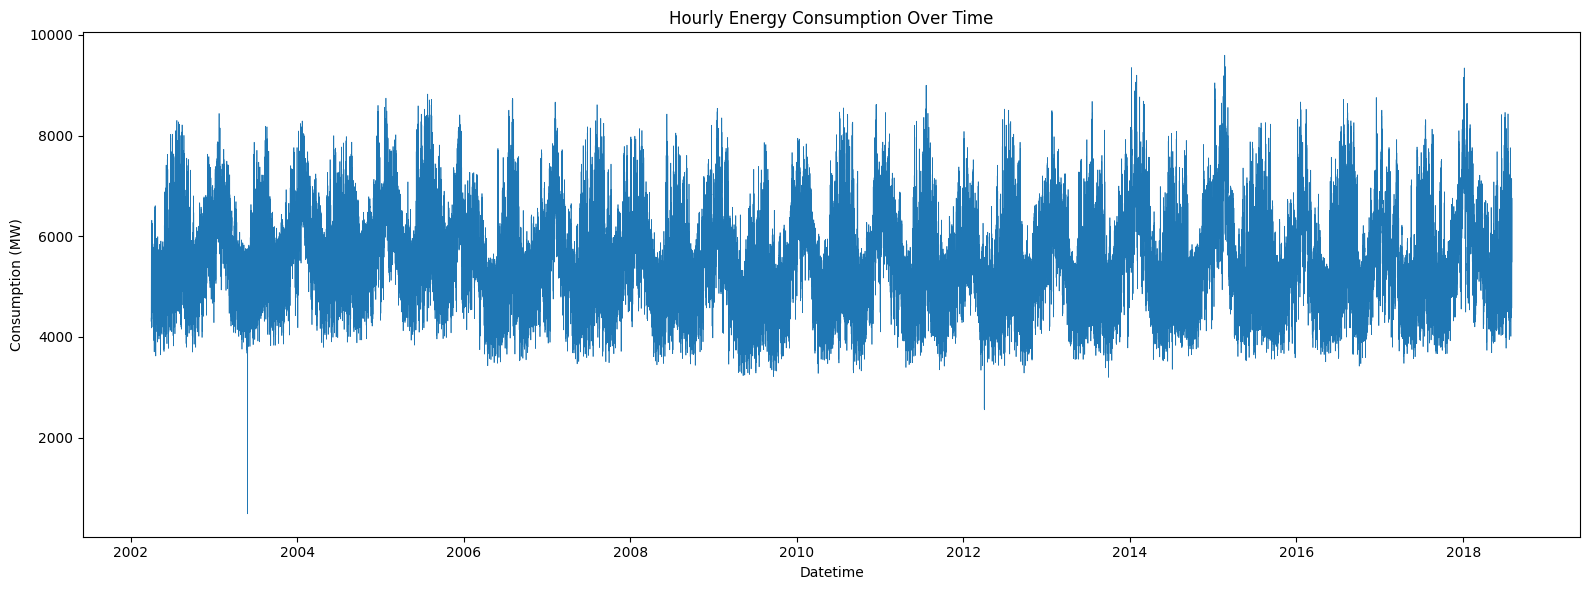

In [45]:
#hourly consumption trend
plt.figure(figsize=(16, 6))

plt.plot(
    df['Datetime'],
    df['PJMW_MW'],
    linewidth=0.5
)

plt.title('Hourly Energy Consumption Over Time')
plt.xlabel('Datetime')
plt.ylabel('Consumption (MW)')
plt.tight_layout()
plt.show()

In [46]:
daily_avg=(df.set_index('Datetime')['PJMW_MW'].resample('D').mean())
daily_avg


Datetime
2002-04-01    5271.173913
2002-04-02    5310.416667
2002-04-03    5325.916667
2002-04-04    5670.791667
2002-04-05    5686.125000
                 ...     
2018-07-30    5492.708333
2018-07-31    5660.750000
2018-08-01    5959.708333
2018-08-02    5805.041667
2018-08-03    5489.000000
Freq: D, Name: PJMW_MW, Length: 5969, dtype: float64

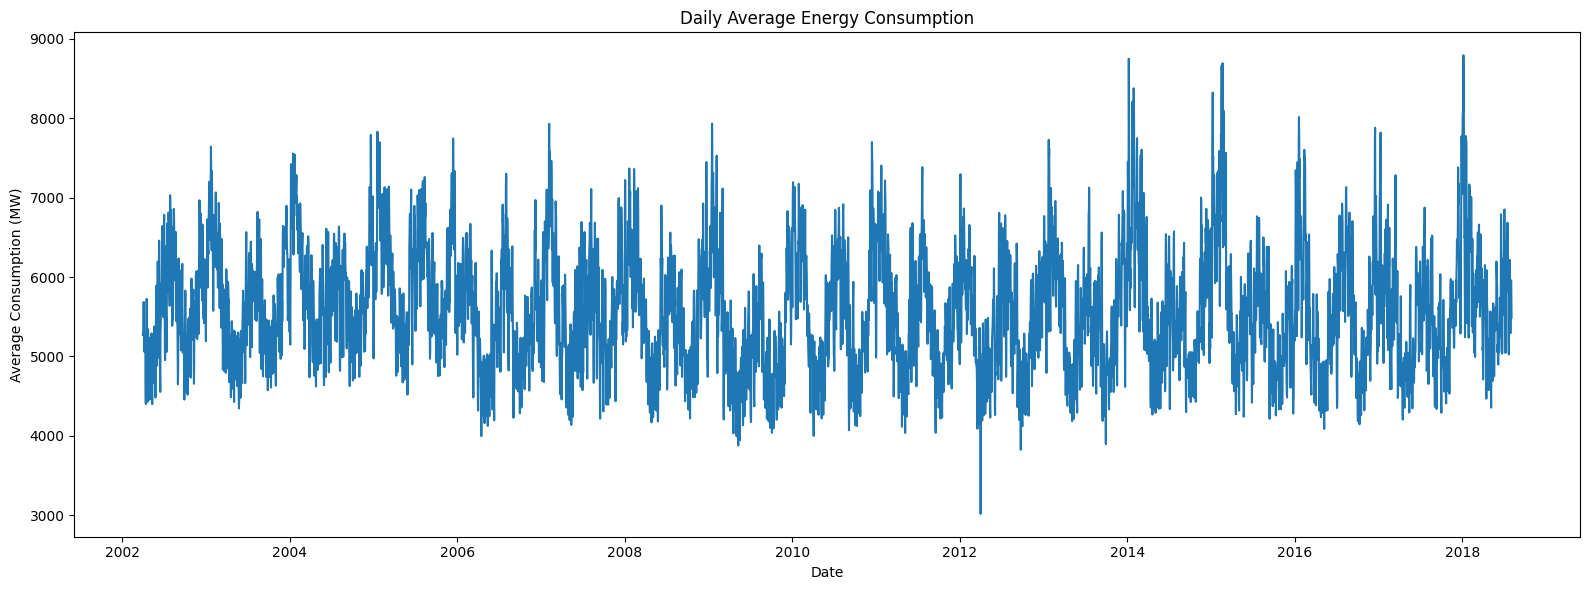

In [47]:
#plotting the daily consumption
plt.figure(figsize=(16, 6))
plt.plot(daily_avg.index, daily_avg.values)

plt.title('Daily Average Energy Consumption')
plt.xlabel('Date')
plt.ylabel('Average Consumption (MW)')
plt.tight_layout()
plt.show()

In [48]:
monthly_avg=(df.set_index('Datetime')['PJMW_MW'].resample('ME').mean())
monthly_avg

Datetime
2002-04-30    5171.318942
2002-05-31    5085.094086
2002-06-30    5685.681944
2002-07-31    6097.877688
2002-08-31    6063.909946
                 ...     
2018-04-30    5281.277778
2018-05-31    5278.620968
2018-06-30    5559.326389
2018-07-31    5978.728495
2018-08-31    5874.346939
Freq: ME, Name: PJMW_MW, Length: 197, dtype: float64

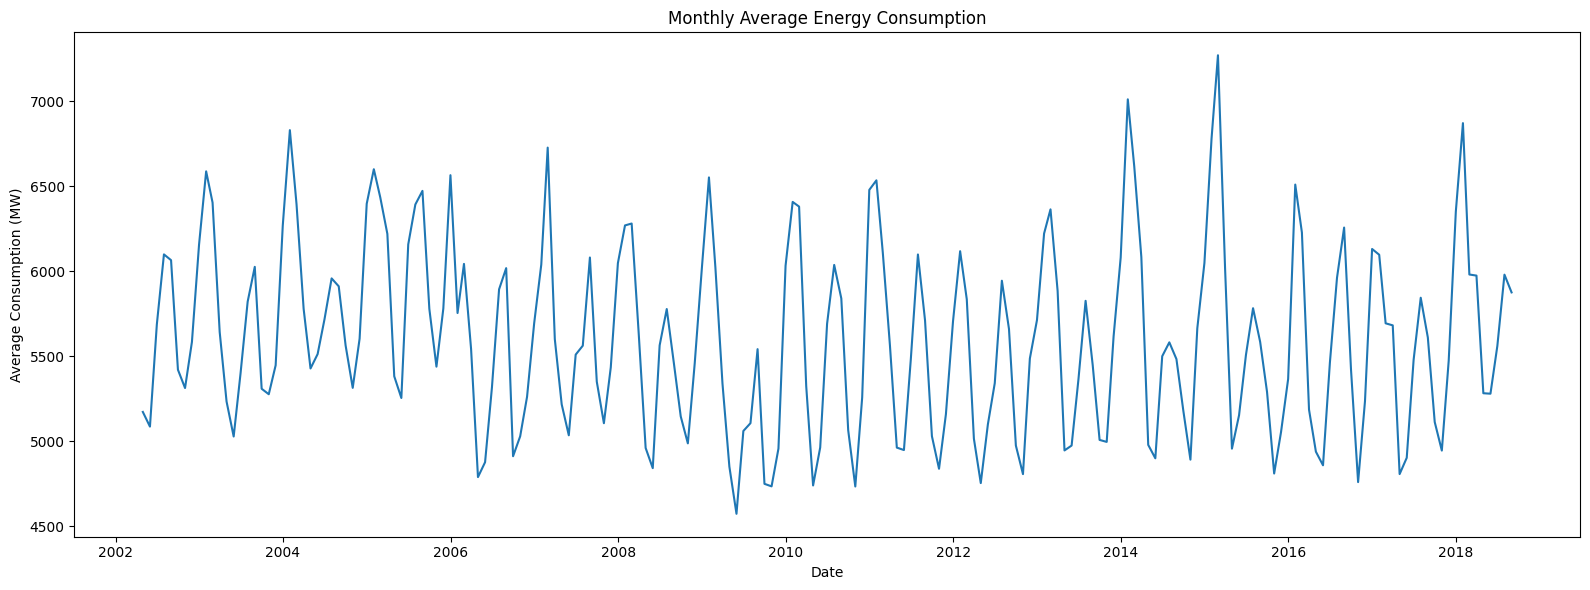

In [49]:
#plotting the daily consumption
plt.figure(figsize=(16, 6))
plt.plot(monthly_avg.index, monthly_avg.values)

plt.title('Monthly Average Energy Consumption')
plt.xlabel('Date')
plt.ylabel('Average Consumption (MW)')
plt.tight_layout()
plt.show()

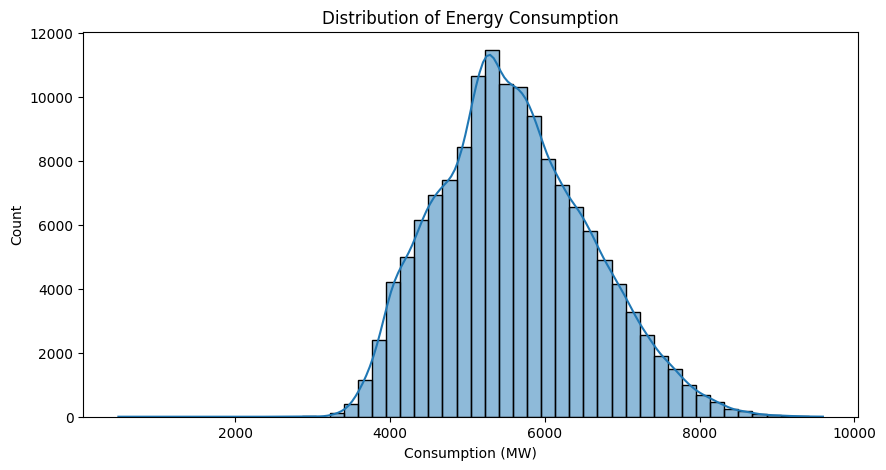

In [50]:
#Distribution of consumption
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='PJMW_MW',
    bins=50,
    kde=True
)

plt.title('Distribution of Energy Consumption')
plt.xlabel('Consumption (MW)')
plt.show()

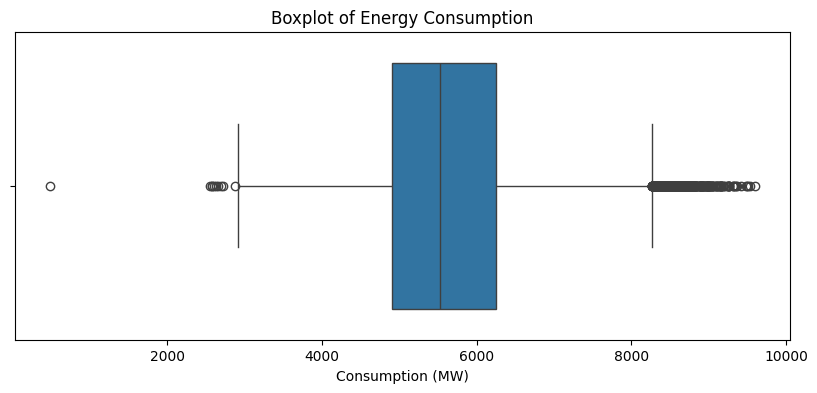

In [51]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df['PJMW_MW'])

plt.title('Boxplot of Energy Consumption')
plt.xlabel('Consumption (MW)')
plt.show()

In [52]:
df['hour']=df['Datetime'].dt.hour
df['day']=df['Datetime'].dt.day
df['day_of_week']=df['Datetime'].dt.dayofweek
df['month']=df['Datetime'].dt.month
df['year']=df['Datetime'].dt.year
df['day_of_year']=df['Datetime'].dt.dayofyear

In [53]:
df.head()

,Datetime,PJMW_MW,hour,day,day_of_week,month,year,day_of_year
0,2002-04-01 01:00:00,4374,1,1,0,4,2002,91
1,2002-04-01 02:00:00,4306,2,1,0,4,2002,91
2,2002-04-01 03:00:00,4322,3,1,0,4,2002,91
3,2002-04-01 04:00:00,4359,4,1,0,4,2002,91
4,2002-04-01 05:00:00,4436,5,1,0,4,2002,91


In [54]:
hourly_avg=df.groupby('hour')['PJMW_MW'].mean()
hourly_avg

hour
0     5230.368359
1     4940.489276
2     4779.152349
3     4697.121996
4     4672.537366
5     4734.933479
6     4958.209450
7     5323.434316
8     5571.168398
9     5708.667058
10    5818.219169
11    5904.120476
12    5947.523794
13    5959.946716
14    5970.935824
15    5953.164712
16    5957.636394
17    6031.231233
18    6158.806803
19    6199.285355
20    6183.568365
21    6152.210121
22    5982.300436
23    5618.226206
Name: PJMW_MW, dtype: float64

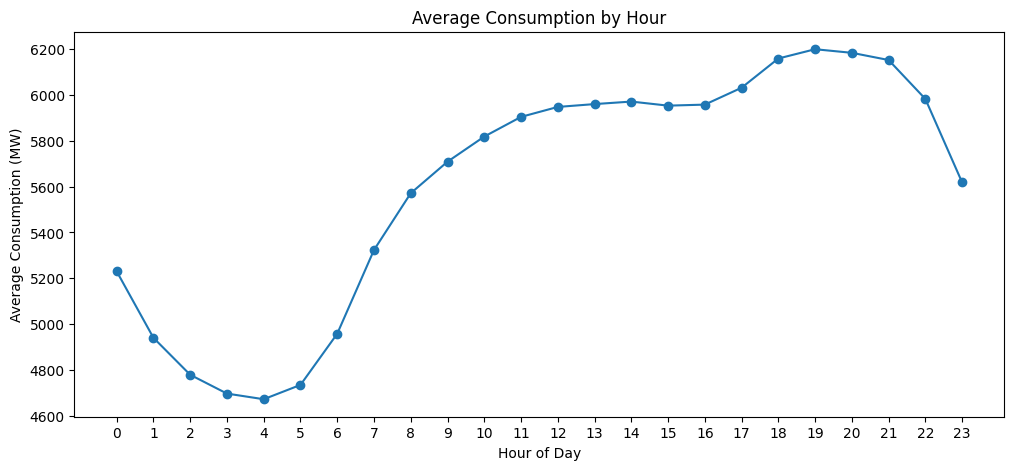

In [55]:

plt.figure(figsize=(12, 5))

plt.plot(hourly_avg.index, hourly_avg.values, marker='o')

plt.xticks(range(24))
plt.xlabel('Hour of Day')
plt.ylabel('Average Consumption (MW)')
plt.title('Average Consumption by Hour')

plt.show()

In [56]:
import numpy as np
df['day_type'] = np.where(
    df['day_of_week'] < 5,
    'Weekday',
    'Weekend'
)

In [57]:
day_type_avg = df.groupby('day_type')['PJMW_MW'].mean()

print(day_type_avg)

day_type
Weekday    5754.345669
Weekend    5221.863008
Name: PJMW_MW, dtype: float64


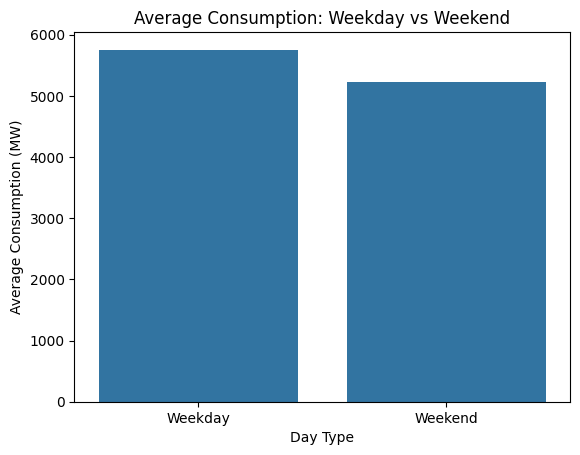

In [58]:
sns.barplot(
    data=df,
    x='day_type',
    y='PJMW_MW',
    order=['Weekday', 'Weekend'],
    errorbar=None
)

plt.title('Average Consumption: Weekday vs Weekend')
plt.xlabel('Day Type')
plt.ylabel('Average Consumption (MW)')
plt.show()

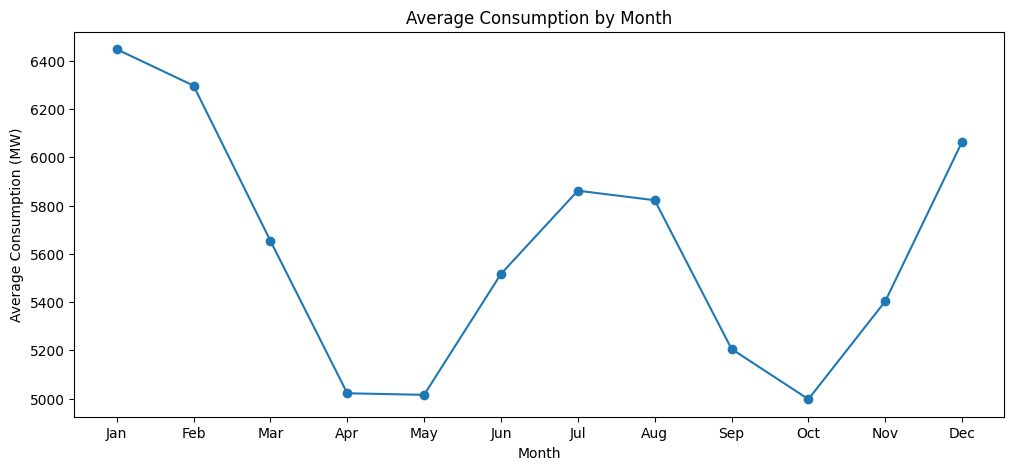

In [59]:
month_avg = df.groupby('month')['PJMW_MW'].mean()

month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

plt.figure(figsize=(12, 5))
plt.plot(month_avg.index, month_avg.values, marker='o')

plt.xticks(range(1, 13), month_names)
plt.xlabel('Month')
plt.ylabel('Average Consumption (MW)')
plt.title('Average Consumption by Month')

plt.show()

In [60]:
hour_month = df.pivot_table(
    values='PJMW_MW',
    index='hour',
    columns='month',
    aggfunc='mean'
)
hour_month

month,1,2,3,4,5,6,7,8,9,10,11,12
hour,,,,,,,,,,,,
0,6066.701613,5965.500000,5325.233871,4690.776031,4654.371917,5133.729412,5460.648956,5385.723447,4778.172917,4615.645161,5030.941667,5739.733333
1,5846.125000,5756.856195,5117.151210,4447.550980,4348.996205,4737.149020,5039.225806,4985.383534,4460.281250,4364.786290,4816.300000,5469.258065
2,5744.000000,5664.373894,5021.641129,4324.039216,4178.210626,4493.323529,4762.104364,4730.937751,4270.660417,4230.904277,4714.008386,5329.459677
3,5714.372984,5639.356195,5001.956612,4276.259406,4083.990512,4346.854902,4585.269450,4569.746988,4159.691667,4170.729839,4676.522917,5277.020161
4,5733.824597,5665.035398,5020.395161,4283.160784,4051.110057,4266.764706,4478.612903,4475.813253,4103.233333,4161.699597,4691.243750,5284.034274
5,5836.754032,5774.393805,5134.528226,4371.398039,4100.130930,4276.674510,4465.341556,4474.913655,4131.070833,4232.445565,4794.381250,5382.586694
6,6105.453629,6051.477876,5419.360887,4631.650980,4311.036053,4427.547059,4594.208729,4630.726908,4327.906250,4476.675403,5058.602083,5632.471774
7,6522.723790,6493.586283,5868.661290,5051.403922,4634.654649,4661.156863,4782.825427,4897.935743,4718.191667,4921.782258,5482.739583,6039.893145
8,6790.247984,6708.566372,6089.157258,5265.805882,4897.901328,4985.056863,5089.514231,5127.329317,4909.970833,5180.645161,5687.981250,6304.316532


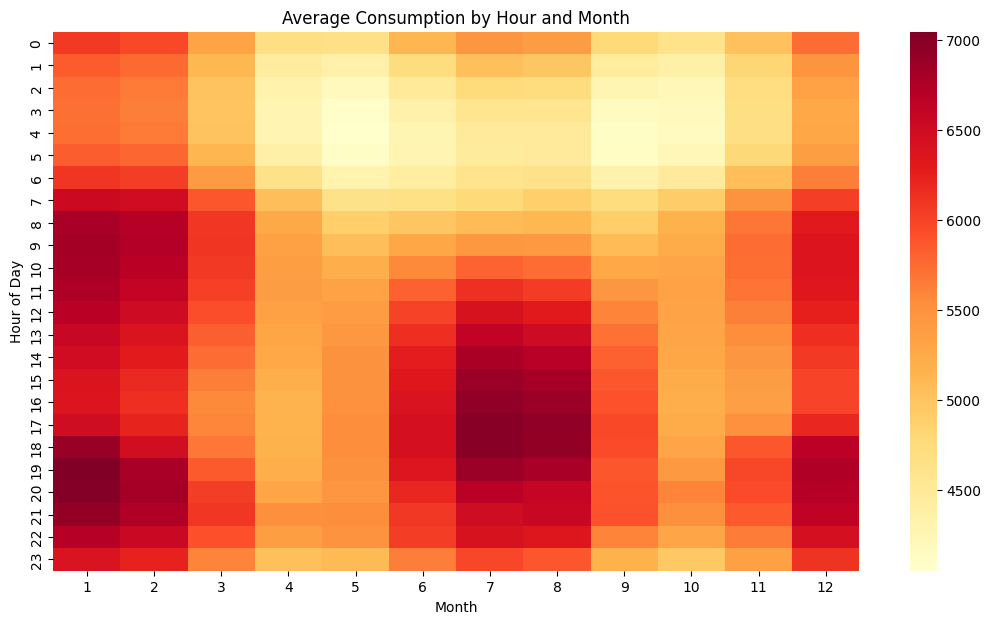

In [61]:
plt.figure(figsize=(13, 7))

sns.heatmap(
    hour_month,
    cmap='YlOrRd'
)

plt.title('Average Consumption by Hour and Month')
plt.xlabel('Month')
plt.ylabel('Hour of Day')

plt.show()

In [62]:
hour_weekday = df.pivot_table(
    values='PJMW_MW',
    index='hour',
    columns='day_of_week',
    aggfunc='mean'
)
hour_weekday

day_of_week,0,1,2,3,4,5,6
hour,,,,,,,
0,5036.051643,5330.651817,5364.967175,5357.437280,5348.674883,5205.454225,4968.916667
1,4792.493552,5034.437280,5064.416178,5061.423212,5047.160798,4896.971831,4686.298122
2,4676.717468,4871.892145,4898.303634,4895.751465,4878.413146,4713.881455,4516.374408
3,4625.826495,4791.808910,4816.087925,4814.690504,4795.311033,4616.784038,4413.378443
4,4625.635404,4773.962485,4796.584994,4792.913247,4771.491784,4572.684272,4374.138498
5,4722.240328,4859.350528,4879.528722,4871.808910,4844.322770,4588.480047,4378.341549
6,5008.641266,5147.001172,5158.650645,5151.430246,5106.062207,4689.426056,4445.511737
7,5465.298945,5616.758499,5627.273154,5616.162954,5544.238263,4840.338028,4552.759390
8,5746.415006,5879.864009,5884.920281,5874.589683,5807.815728,5054.713615,4748.568075


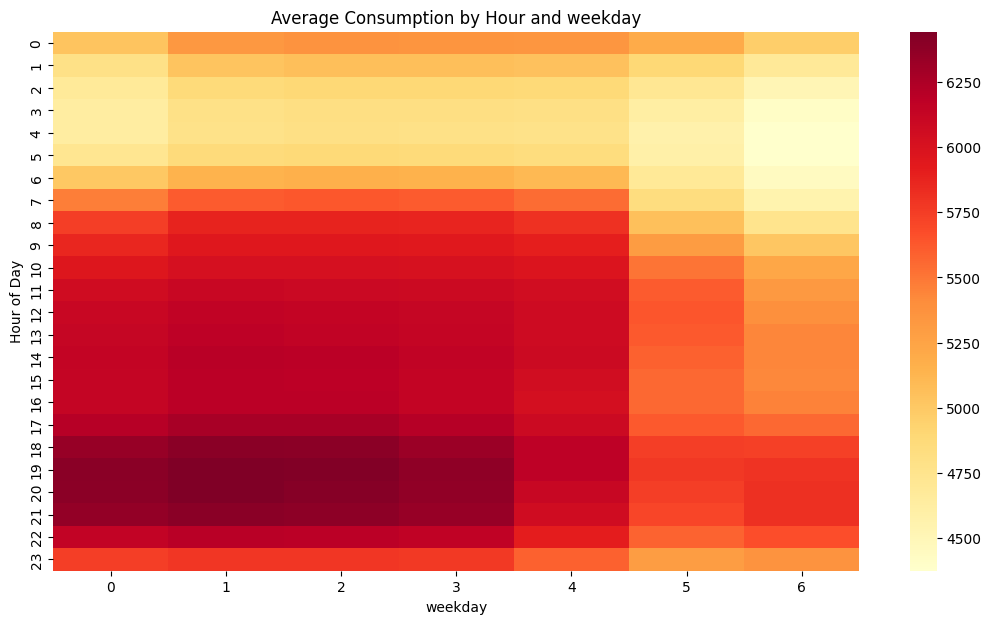

In [63]:
plt.figure(figsize=(13, 7))

sns.heatmap(
    hour_weekday,
    cmap='YlOrRd'
)

plt.title('Average Consumption by Hour and weekday')
plt.xlabel('weekday')
plt.ylabel('Hour of Day')

plt.show()

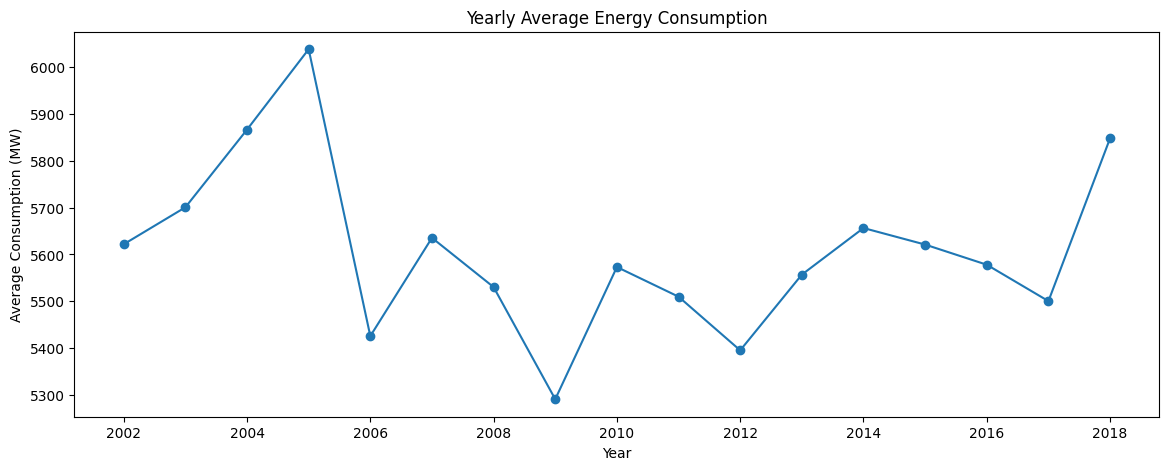

In [64]:
yearly_avg = df.groupby('year')['PJMW_MW'].mean()

plt.figure(figsize=(14, 5))
plt.plot(yearly_avg.index, yearly_avg.values, marker='o')

plt.xlabel('Year')
plt.ylabel('Average Consumption (MW)')
plt.title('Yearly Average Energy Consumption')

plt.show()

In [65]:
df = df.sort_values('Datetime').reset_index(drop=True)

In [66]:
df.head()

,Datetime,PJMW_MW,hour,day,day_of_week,month,year,day_of_year,day_type
0,2002-04-01 01:00:00,4374,1,1,0,4,2002,91,Weekday
1,2002-04-01 02:00:00,4306,2,1,0,4,2002,91,Weekday
2,2002-04-01 03:00:00,4322,3,1,0,4,2002,91,Weekday
3,2002-04-01 04:00:00,4359,4,1,0,4,2002,91,Weekday
4,2002-04-01 05:00:00,4436,5,1,0,4,2002,91,Weekday


In [67]:
df['lag_1'] = df['PJMW_MW'].shift(1)

In [68]:
df.head()

,Datetime,PJMW_MW,hour,day,day_of_week,month,year,day_of_year,day_type,lag_1
0,2002-04-01 01:00:00,4374,1,1,0,4,2002,91,Weekday,NaN
1,2002-04-01 02:00:00,4306,2,1,0,4,2002,91,Weekday,4374.0
2,2002-04-01 03:00:00,4322,3,1,0,4,2002,91,Weekday,4306.0
3,2002-04-01 04:00:00,4359,4,1,0,4,2002,91,Weekday,4322.0
4,2002-04-01 05:00:00,4436,5,1,0,4,2002,91,Weekday,4359.0


In [69]:
df['lag_24']=df['PJMW_MW'].shift(24)

In [70]:
df.head()

,Datetime,PJMW_MW,hour,day,day_of_week,month,year,day_of_year,day_type,lag_1,lag_24
0,2002-04-01 01:00:00,4374,1,1,0,4,2002,91,Weekday,NaN,NaN
1,2002-04-01 02:00:00,4306,2,1,0,4,2002,91,Weekday,4374.0,NaN
2,2002-04-01 03:00:00,4322,3,1,0,4,2002,91,Weekday,4306.0,NaN
3,2002-04-01 04:00:00,4359,4,1,0,4,2002,91,Weekday,4322.0,NaN
4,2002-04-01 05:00:00,4436,5,1,0,4,2002,91,Weekday,4359.0,NaN


In [71]:
df['lag_168'] = df['PJMW_MW'].shift(168)

In [72]:
df.head()

,Datetime,PJMW_MW,hour,day,day_of_week,month,year,day_of_year,day_type,lag_1,lag_24,lag_168
0,2002-04-01 01:00:00,4374,1,1,0,4,2002,91,Weekday,NaN,NaN,NaN
1,2002-04-01 02:00:00,4306,2,1,0,4,2002,91,Weekday,4374.0,NaN,NaN
2,2002-04-01 03:00:00,4322,3,1,0,4,2002,91,Weekday,4306.0,NaN,NaN
3,2002-04-01 04:00:00,4359,4,1,0,4,2002,91,Weekday,4322.0,NaN,NaN
4,2002-04-01 05:00:00,4436,5,1,0,4,2002,91,Weekday,4359.0,NaN,NaN


In [73]:
df['rolling_24'] = (
    df['PJMW_MW']
      .shift(1)
      .rolling(window=24)
      .mean()
)

In [74]:
df.head(30)

,Datetime,PJMW_MW,hour,day,day_of_week,month,year,day_of_year,day_type,lag_1,lag_24,lag_168,rolling_24
0,2002-04-01 01:00:00,4374,1,1,0,4,2002,91,Weekday,NaN,NaN,NaN,NaN
1,2002-04-01 02:00:00,4306,2,1,0,4,2002,91,Weekday,4374.0,NaN,NaN,NaN
2,2002-04-01 03:00:00,4322,3,1,0,4,2002,91,Weekday,4306.0,NaN,NaN,NaN
3,2002-04-01 04:00:00,4359,4,1,0,4,2002,91,Weekday,4322.0,NaN,NaN,NaN
4,2002-04-01 05:00:00,4436,5,1,0,4,2002,91,Weekday,4359.0,NaN,NaN,NaN
5,2002-04-01 06:00:00,4723,6,1,0,4,2002,91,Weekday,4436.0,NaN,NaN,NaN
6,2002-04-01 07:00:00,5180,7,1,0,4,2002,91,Weekday,4723.0,NaN,NaN,NaN
7,2002-04-01 08:00:00,5482,8,1,0,4,2002,91,Weekday,5180.0,NaN,NaN,NaN
8,2002-04-01 09:00:00,5616,9,1,0,4,2002,91,Weekday,5482.0,NaN,NaN,NaN
9,2002-04-01 10:00:00,5722,10,1,0,4,2002,91,Weekday,5616.0,NaN,NaN,NaN


In [75]:
df['rolling_168'] = (
    df['PJMW_MW']
      .shift(1)
      .rolling(window=168)
      .mean()
)

In [76]:
df[
    ['Datetime', 'PJMW_MW', 'lag_24',
     'lag_168', 'rolling_24', 'rolling_168']
].tail(20)

,Datetime,PJMW_MW,lag_24,lag_168,rolling_24,rolling_168
143186,2018-08-02 05:00:00,4594,4565.0,4636.0,5964.875000,5726.767857
143187,2018-08-02 06:00:00,4826,4815.0,4850.0,5966.083333,5726.517857
143188,2018-08-02 07:00:00,5114,5135.0,5117.0,5966.541667,5726.375000
143189,2018-08-02 08:00:00,5333,5509.0,5401.0,5965.666667,5726.357143
143190,2018-08-02 09:00:00,5597,5644.0,5693.0,5958.333333,5725.952381
143191,2018-08-02 10:00:00,5775,5846.0,5904.0,5956.375000,5725.380952
143192,2018-08-02 11:00:00,6050,6165.0,6313.0,5953.416667,5724.613095
143193,2018-08-02 12:00:00,6152,6419.0,6693.0,5948.625000,5723.047619
143194,2018-08-02 13:00:00,6299,6614.0,7022.0,5937.500000,5719.827381
143195,2018-08-02 14:00:00,6425,6853.0,7233.0,5924.375000,5715.523810


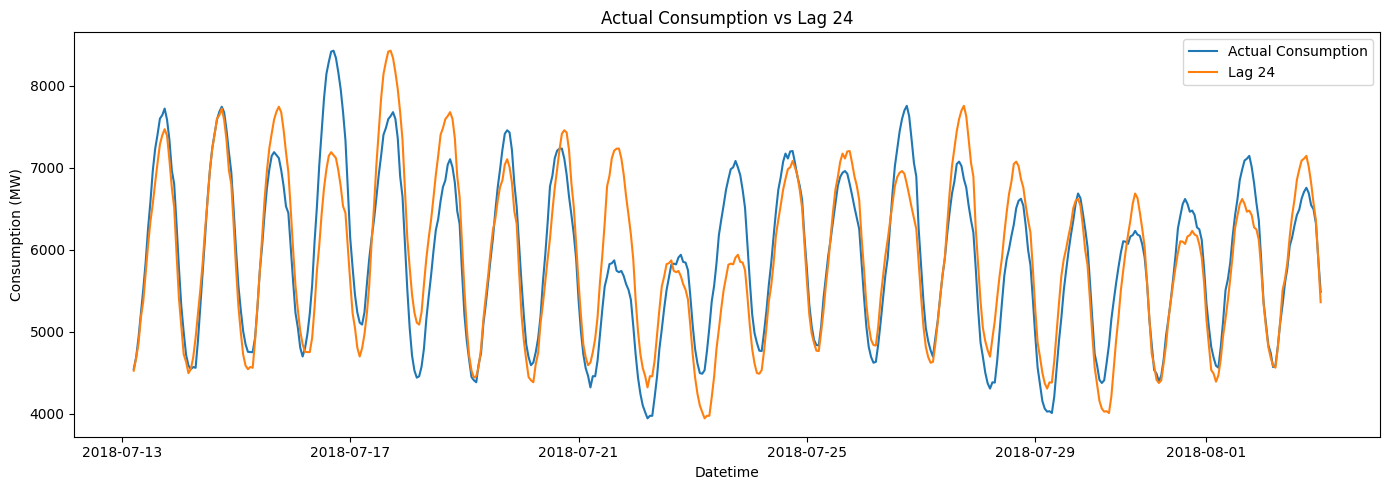

In [77]:
#Plot consumption against its lags
sample = df.dropna(subset=['lag_24']).tail(500)

plt.figure(figsize=(14, 5))

plt.plot(
    sample['Datetime'],
    sample['PJMW_MW'],
    label='Actual Consumption'
)

plt.plot(
    sample['Datetime'],
    sample['lag_24'],
    label='Lag 24'
)

plt.xlabel('Datetime')
plt.ylabel('Consumption (MW)')
plt.title('Actual Consumption vs Lag 24')
plt.legend()
plt.tight_layout()
plt.show()

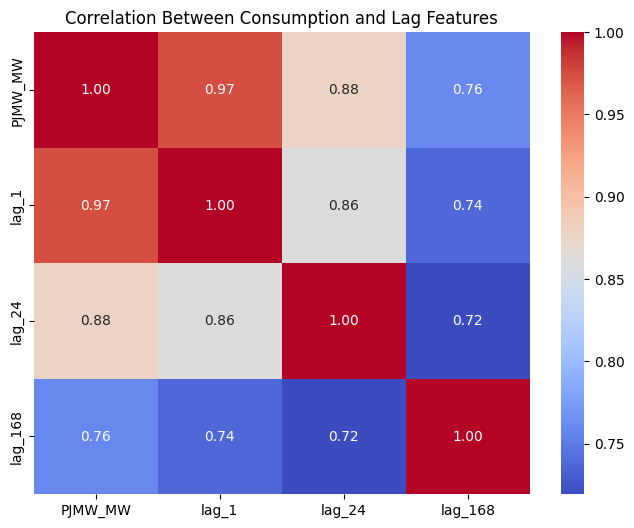

In [78]:
lag_columns = [
    'PJMW_MW',
    'lag_1',
    'lag_24',
    'lag_168'
]

lag_corr = df[lag_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    lag_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Consumption and Lag Features')
plt.show()

In [79]:
df.head()

,Datetime,PJMW_MW,hour,day,day_of_week,month,year,day_of_year,day_type,lag_1,lag_24,lag_168,rolling_24,rolling_168
0,2002-04-01 01:00:00,4374,1,1,0,4,2002,91,Weekday,NaN,NaN,NaN,NaN,NaN
1,2002-04-01 02:00:00,4306,2,1,0,4,2002,91,Weekday,4374.0,NaN,NaN,NaN,NaN
2,2002-04-01 03:00:00,4322,3,1,0,4,2002,91,Weekday,4306.0,NaN,NaN,NaN,NaN
3,2002-04-01 04:00:00,4359,4,1,0,4,2002,91,Weekday,4322.0,NaN,NaN,NaN,NaN
4,2002-04-01 05:00:00,4436,5,1,0,4,2002,91,Weekday,4359.0,NaN,NaN,NaN,NaN


In [93]:
def adfuller_test(series):
    result=adfuller(series)
    return {
        "ADF statistics":result[0],
        'p-value':result[1]
    }
adfuller_result=adfuller_test(df["PJMW_MW"])
adfuller_result

{'ADF statistics': np.float64(-19.530978788978132), 'p-value': 0.0}

# Model Building